In [4]:
from ultralytics import YOLO
from getpass import getpass
from roboflow import Roboflow

In [5]:
rf = Roboflow(api_key=getpass("Roboflow API key: "))
project = rf.workspace("jhazmine-therese-roque-biwst").project("emotion-detection-ooj7h")
dataset = project.version(4).download("yolov8", location="datasets/emotions")
print(dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to datasets/emotions in yolov8:: 100%|██████████| 11210/11210 [00:01<00:00, 7452.90it/s]

/workspaces/edu-grafika-lab3/datasets/emotions


train: 4487 frames, 0 images without frames
{'Angry': 642, 'Disgusted': 644, 'Fearful': 634, 'Happy': 639, 'Neutral': 640, 'Sad': 640, 'Surprised': 648}
valid: 550 frames, 0 images without frames
{'Angry': 79, 'Disgusted': 78, 'Fearful': 83, 'Happy': 73, 'Neutral': 74, 'Sad': 85, 'Surprised': 78}
test: 566 frames, 0 images without frames
{'Angry': 80, 'Disgusted': 78, 'Fearful': 83, 'Happy': 91, 'Neutral': 85, 'Sad': 75, 'Surprised': 74}


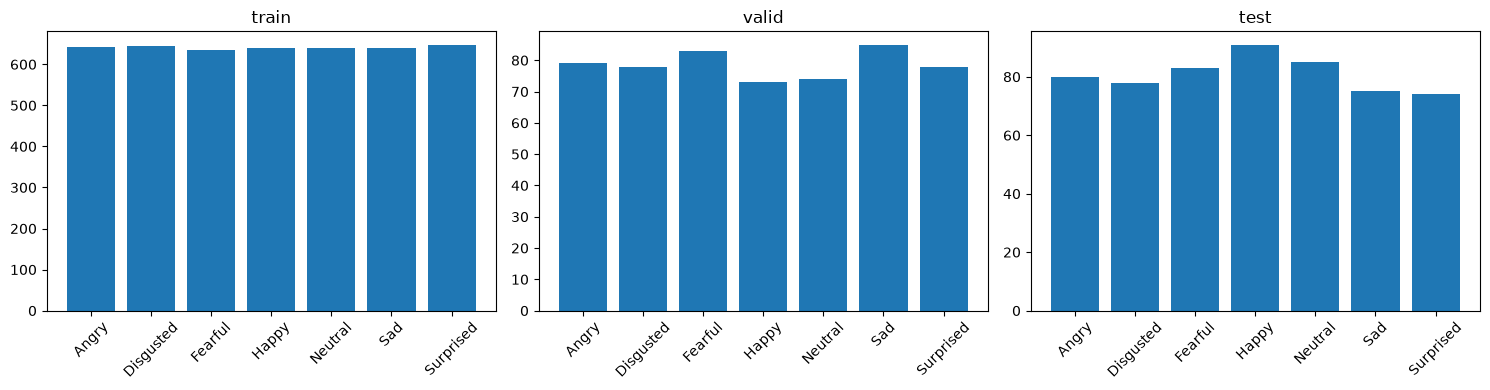

In [7]:
from pathlib import Path
from collections import Counter
import matplotlib.pyplot as plt

DATASET_DIR = Path("datasets/emotions")
NAMES = ["Angry", "Disgusted", "Fearful", "Happy", "Neutral", "Sad", "Surprised"]

def count_classes(split):
    counts, empty = Counter(), 0
    for f in (DATASET_DIR / split / "labels").glob("*.txt"):
        lines = f.read_text().strip().splitlines()
        if not lines:
            empty += 1
        for line in lines:
            counts[int(line.split()[0])] += 1
    return counts, empty

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for ax, split in zip(axes, ["train", "valid", "test"]):
    counts, empty = count_classes(split)
    print(f"{split}: {sum(counts.values())} frames, {empty} images without frames")
    print({NAMES[i]: counts[i] for i in range(7)})
    ax.bar(NAMES, [counts[i] for i in range(7)])
    ax.set_title(split)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()